In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import pchip_interpolate

from igs_ga.optimization.modo import Preferendus

In [2]:
# Define preference functions for the two objectives
def p_shopping_value(x1, x2):
    """Objective to maximize the shopping added value.

    :param x1: 1st design variable
    :param x2: 2nd design variable
    """
    normalized_x1 = 1 - (x1 - 100) / (1000 - 100)
    normalized_x2 = (x2 - 800) / (30_000 - 800)

    # Performance measure for shopping value
    o_sp = np.sqrt(normalized_x1 ** 2 + normalized_x2 ** 2)

    # Preference mapping: o_sp -> p_sp using PCHIP anchors
    return pchip_interpolate([0, 1, np.sqrt(2)], [0, 100, 60], o_sp)


def p_sustainability(x1, x2):
    """Objective that describes the relative sustainability.

    :param x1: 1st design variable
    :param x2: 2nd design variable
    """
    # Performance measure for sustainability index
    o_sus = x2 / (20_000 * x1 / 400)

    # Preference mapping: o_sus -> p_sus using PCHIP anchors
    return pchip_interpolate([0, 4, 6], [0, 100, 60], o_sus)

In [3]:
# Set weights for the different objectives
w1 = 0.65
w2 = 0.35

# Define stakeholder preferences
stakeholder_preferences = {
    1: {
        "1_shopping": lambda x: x if 0 <= x <= 100 else (0 if x > 100 else 0),
        "2_sustainability": lambda x: x if 0 <= x <= 100 else (100 if x > 100 else 0),
    },
}

# Set objective weights
objective_weights = {
    1: {"1_shopping": w1, "2_sustainability": w2},
}

In [4]:
# Set optimization options
optimization_options = {
    'population_size': 50,
    'generations': 200,
    'mutation_rate': 0.80,
    'max_stall': 10,
    'hall_of_fame_size':10
}

@Preferendus(
    preference_functions=stakeholder_preferences,
    stakeholder_weights=[1.0],
    variable_types=[float, int],
    value_range=[(100.0, 1000.0), (800, 30000)],
    objective_weights=objective_weights,
    optimization_options=optimization_options
)
def run_simulation(x):
    """Objective function that calculates the two objectives for the supermarket problem.

    :param x: Design variables [x1, x2] where x1 is distance in meters and x2 is number of products
    :return: None, None, plus the two objective values
    """
    # Calculate the shopping value preference
    shopping_value = p_shopping_value(x[0], x[1])

    # Calculate the sustainability preference
    sustainability = p_sustainability(x[0], x[1])

    return None, None, shopping_value, sustainability
# Run the optimization
initial_guess = [147, 11370]  # Initial guess in the middle of the bounds
result = run_simulation(initial_guess)

# Extract optimal design variables
design_variables = result['x_opt']

print(f'Optimal result for a distance of {round(design_variables[0], 2)} meters and '
      f'{design_variables[1]} products')
print(f"Utility: {result['utility']}")

Generation  Best score  Infeasible  Stall   Gene mutation rate
1           50.00       0           1       0.03962     
2           100.00      0           0       0.04003     
3           100.00      0           1       0.03807     
4           100.00      0           2       0.03823     
5           100.00      0           0       0.03764     
6           100.00      0           1       0.03852     
7           100.00      0           0       0.03918     
8           100.00      0           1       0.03846     
9           100.00      0           0       0.03904     
10          100.00      0           0       0.03841     
11          100.00      0           0       0.03689     
12          100.00      0           1       0.0355      
13          100.00      0           0       0.03705     
14          100.00      0           0       0.03755     
15          100.00      0           1       0.04015     
16          100.00      0           2       0.03944     
17          100.00      0

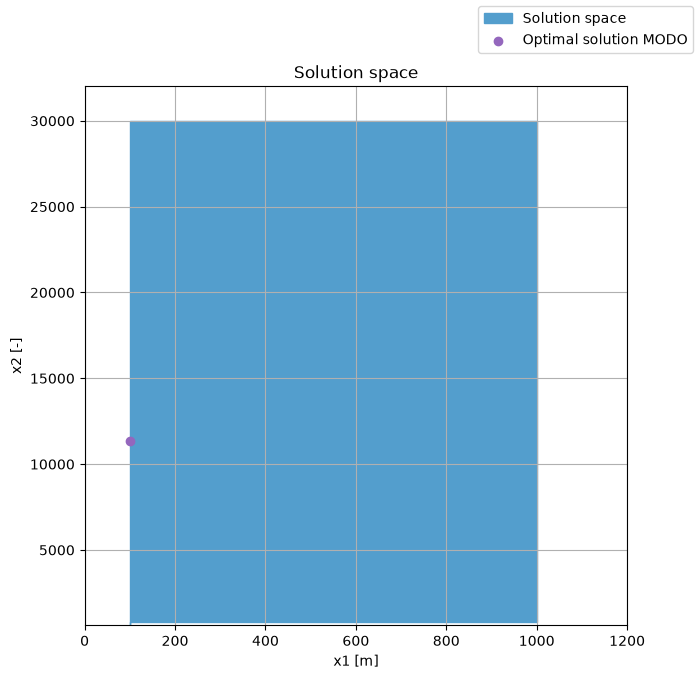

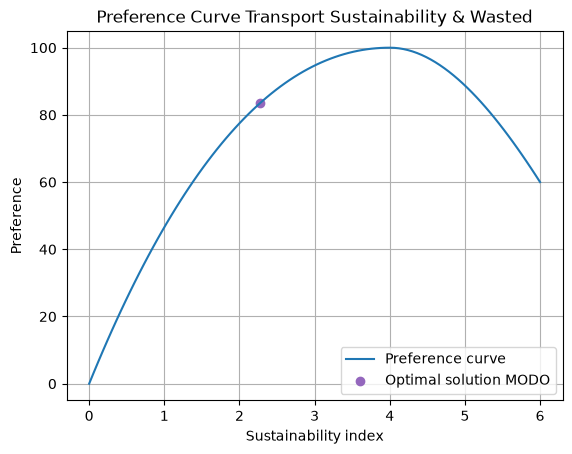

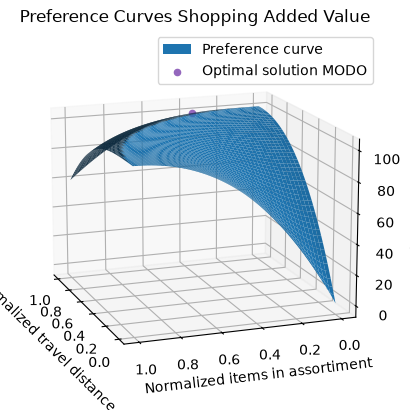

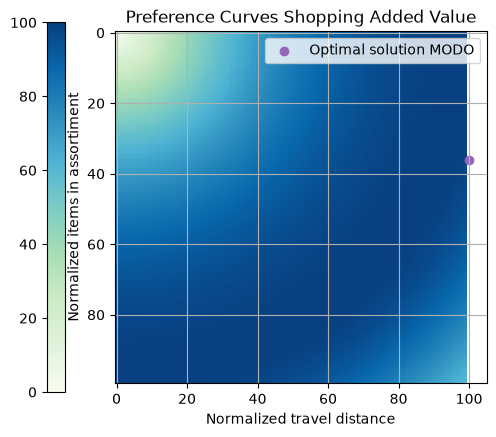

In [5]:
# Create figure that shows the results in the solution space
fig, ax = plt.subplots(figsize=(7, 7))
ax.set_xlim((0, 1200))
ax.set_ylim((600, 32_000))
ax.set_xlabel('x1 [m]')
ax.set_ylabel('x2 [-]')
ax.set_title('Solution space')

# Define corner points of solution space
x_fill = [100, 1000, 1000, 100]
y_fill = [30_000, 30_000, 800, 800]

ax.fill_between(x_fill, y_fill, color='#539ecd', label='Solution space')
ax.scatter(design_variables[0], design_variables[1], label='Optimal solution MODO', color='tab:purple')

ax.grid()  # show grid
fig.legend()  # show legend

# Create arrays for plotting continuous preference curves
c1 = np.linspace(0, 2, 100)
c2 = np.linspace(0, 6, 100)

# Calculate the preference functions (same curves as p_shopping_value and p_sustainability)
norm_1 = np.linspace(0, 1, 100)
norm_2 = np.linspace(0, 1, 100)
N1, N2 = np.meshgrid(norm_1, norm_2)

p1 = pchip_interpolate([0, 1, np.sqrt(2)], [0, 100, 60], np.sqrt(N1 ** 2 + N2 ** 2))
p2 = pchip_interpolate([0, 4, 6], [0, 100, 60], c2)

# Calculate individual preference scores for the results to plot them on the preference curves
normalized_c1x1 = 1 - (design_variables[0] - 100) / (1000 - 100)
normalized_c1x2 = (design_variables[1] - 800) / (30_000 - 800)

c2_res = design_variables[1] / (20_000 * design_variables[0] / 400)

p1_res = p_shopping_value(design_variables[0], design_variables[1])
p2_res = p_sustainability(design_variables[0], design_variables[1])

# Create figure that plots all preference curves and the preference scores of the returned results
fig = plt.figure()
ax2 = fig.add_subplot(1, 1, 1)
ax2.plot(c2, p2, label='Preference curve')
ax2.scatter(c2_res, p2_res, label='Optimal solution MODO', color='tab:purple')
ax2.set(xlabel='Sustainability index', ylabel='Preference')
ax2.set_title('Preference Curve Transport Sustainability & Wasted')
ax2.legend()
ax2.grid()

fig = plt.figure()
ax1 = fig.add_subplot(1, 1, 1, projection='3d')
surf = ax1.plot_surface(N1, N2, p1, label='Preference curve')
ax1.scatter(normalized_c1x1, normalized_c1x2, p1_res, label='Optimal solution MODO', color='tab:purple')
ax1.set(xlabel='Normalized travel distance', ylabel='Normalized items in assortiment', zlabel='Preference')
ax1.set_title('Preference Curves Shopping Added Value')
ax1.view_init(elev=15, azim=160)
surf._facecolors2d = surf._facecolor3d
surf._edgecolors2d = surf._edgecolor3d
ax1.legend()
ax1.grid()

fig = plt.figure()
ax3 = fig.add_subplot(1, 1, 1)
img = ax3.imshow(p1, cmap='GnBu', interpolation='nearest')
ax3.scatter(normalized_c1x1 * 100, normalized_c1x2 * 100, label='Optimal solution MODO', color='tab:purple')
ax3.set(xlabel='Normalized travel distance', ylabel='Normalized items in assortiment')
ax3.set_title('Preference Curves Shopping Added Value')
ax3.legend()
ax3.grid()

plt.colorbar(img, ax=ax3, location='left')

plt.show()

In [6]:
import igs_ga
import igs_ga.optimization.optimization as opt_mod
print('igs_ga module:', igs_ga.__file__)
print('optimization module:', opt_mod.__file__)

igs_ga module: C:\Users\emoz\OneDrive - Boskalis\Desktop\Odesys repos\IGS-GA-I\src\igs_ga\__init__.py
optimization module: C:\Users\emoz\OneDrive - Boskalis\Desktop\Odesys repos\IGS-GA-I\src\igs_ga\optimization\optimization.py
